__________________________________________
## **NAME: Muhammad Hassan Irfan**
## **Qalam ID: 464849**
## **Section: BESE-14-A**
____________________________________________
## **NAME: Muneeb Rifaq**
## **Qalam ID: 453438**
## **Section: BESE-14-A**
___________________________________________
------
------

##### CS-405 Deep Learning   
##### BSSE
## **Lab 3: Hyperparameter Tuning in Neural Network — Task 2**

**Date: 25-09-2026**  

**Student name / CMS ID:** Muhammad Hassan Irfan / 464849

**Lab Engineer:** Ms. Areeba Rameen  
**Instructor:** Dr. Muhammad Daud Abdullah Asif

Most machine learning workflows involve working with data, creating models, optimizing model parameters, and saving the trained models. In **Task 2**, we apply the complete PyTorch workflow and hyperparameter tuning techniques from Task 1 to the **Fashion MNIST** dataset.

**Task 2 Goal:**
- Repeat all steps for the Fashion MNIST dataset.
- Apply Question 1 (Width and Depth experiments).
- Apply Question 2 (Learning Rate and Optimizer experiments).
- Apply Question 3 (Epoch experiments: 5, 10, and 50 epochs).
- Address Question 4 (Multiclass activation function & CrossEntropyLoss).
- Record and report accuracies and losses for all experiments.

### **Task 2**

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt
import random
import numpy as np

Check if GPU is available.

In [2]:
use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
print('<== CUDA availability : ==>', use_cuda)
print(f"Using device: {device}")

<== CUDA availability : ==> True
Using device: cuda


Set seed for reproducability.

In [3]:
def set_seeds(seed):
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    random.seed(seed)

set_seeds(42)

PyTorch offers domain-specific libraries such as <b>TorchText, TorchVision, and TorchAudio,</b> all of which include datasets. For this task, we will be using the TorchVision **FashionMNIST** dataset. Load the prebuilt dataset from the PyTorch repository. Currently, we are not using any transform (manipulation) on input data. We are just converting each image to tensor.

In [4]:
# Download training data from open datasets.
training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.2MB/s]


Visualise some of the input images.

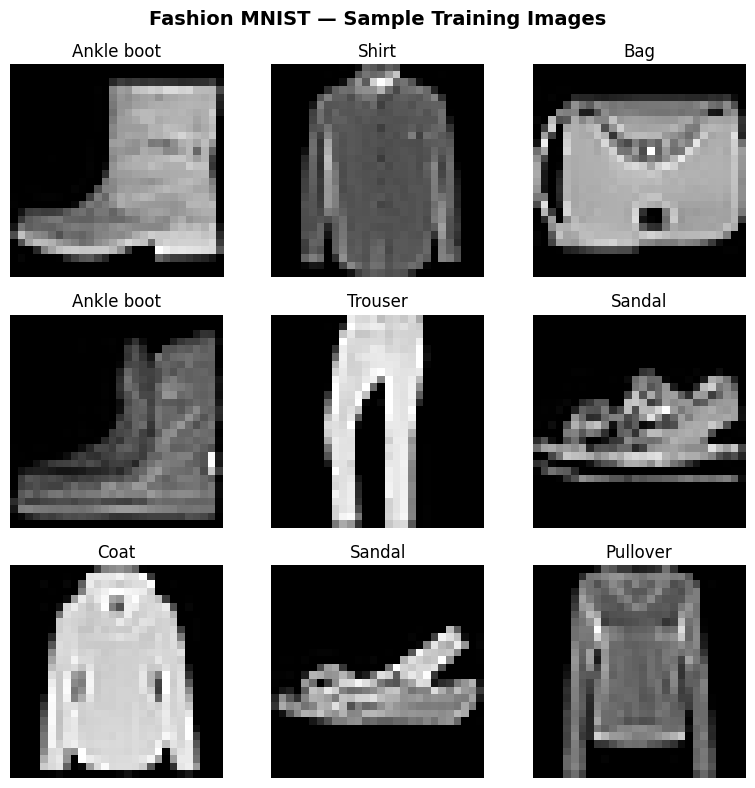

In [5]:
labels_map = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot",
}

figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()  # randomly pick indices from the training data
    img, label = training_data[sample_idx]                            # Read the images using their indices.
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.suptitle("Fashion MNIST — Sample Training Images", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Check the size and shape of training and validation data.

In [6]:
# Visualize the size of the datasets

print(f"Training data size: {len(training_data)} samples")
print(f"Test data size: {len(test_data)} samples")

Training data size: 60000 samples
Test data size: 10000 samples


In [7]:
# Visualize the shape of a single image and its label

train_image, train_label = training_data[0]  # Get the first training sample
test_image, test_label = test_data[0]        # Get the first test sample

print(f"Shape of a training image: {train_image.shape}")  # (1, 28, 28) - 1 channel, 28x28 pixels
print(f"Shape of a test image: {test_image.shape}")
print(f"Training label: {train_label} ({labels_map[train_label]})")
print(f"Test label: {test_label} ({labels_map[test_label]})")

Shape of a training image: torch.Size([1, 28, 28])
Shape of a test image: torch.Size([1, 28, 28])
Training label: 9 (Ankle boot)
Test label: 9 (Ankle boot)


The shape of the training set is (60000, 2). This means that we have 60,000 samples with 2 entities. The first entity is the image and the second entity is its label. For example:

**training_data[0][0]** is the first image of training set

**training_data[0][1]** is the label of the first image in the training set

Now pass the Dataset as an argument to DataLoader. This wraps an iterable over our dataset, and supports automatic batching, sampling, shuffling and multiprocess data loading. Here we define a batch size of 64, i.e. each element in the dataloader iterable will return a batch of 64 features and labels.

In [8]:
batch_size = 64

# Create data loaders.
train_dataloader = DataLoader(training_data, batch_size=batch_size, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")  # [batch_size, channels, height, width]
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


To define a neural network in PyTorch, we create a class that inherits from nn.Module. We define the layers of the network in the __init__ function and specify how data will pass through the network in the forward function. To accelerate operations in the neural network, we move it to the GPU if available.

In [9]:
# Define model
class NeuralNetwork(nn.Module):
    def __init__(self):
        super(NeuralNetwork, self).__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


Now define the loss function and set up optimiser.

In [10]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

Define train function.

In [11]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    running_loss = 0                            # accumulate loss of each input sample
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)       # assign input samples to the available device (CPU or GPU) for computation.

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        optimizer.zero_grad()  # set the gradients to zero to avoid gradient accumulation.
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        if batch % 100 == 0:
            loss, current = loss.item(), batch * len(X)
            #print(f"training loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

    return running_loss / len(dataloader)

Define evaluation function.

In [12]:
def test(dataloader, model, loss_fn, return_acc=True):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():         # No gradients need to be calculated for evaluation. Just the forward pass.
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size               # Normalise correctly classified count.
    accuracy = 100 * correct
    print(f"test loss: \nAccuracy: {accuracy:>0.1f}%, avg loss: {test_loss:>8f} \n")

    if return_acc:
        return test_loss, accuracy
    return test_loss

Initiate Training Process

Epoch 1
-------------------------------
test loss: 
Accuracy: 25.6%, avg loss: 2.218876 

Epoch 2
-------------------------------
test loss: 
Accuracy: 41.2%, avg loss: 2.058267 

Epoch 3
-------------------------------
test loss: 
Accuracy: 54.5%, avg loss: 1.743327 

Epoch 4
-------------------------------
test loss: 
Accuracy: 59.4%, avg loss: 1.407649 

Epoch 5
-------------------------------
test loss: 
Accuracy: 62.8%, avg loss: 1.189867 

Done!


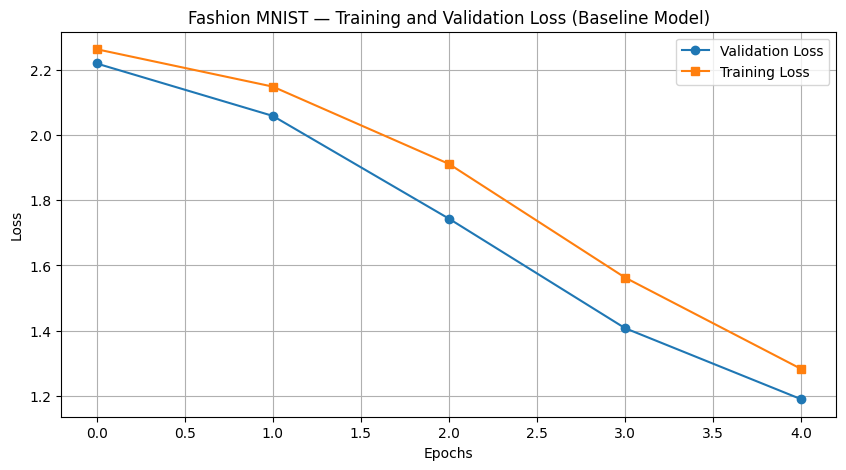

In [13]:
epochs = 5
train_losses = []
test_losses = []
test_accuracies = []

for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")

    train_loss = train(train_dataloader, model, loss_fn, optimizer)
    train_losses.append(train_loss)

    test_loss, test_acc = test(test_dataloader, model, loss_fn)
    test_losses.append(test_loss)
    test_accuracies.append(test_acc)

print("Done!")

# Plot training and validation losses.
plt.figure(figsize=(10, 5))
plt.title("Fashion MNIST — Training and Validation Loss (Baseline Model)")
plt.plot(test_losses, label="Validation Loss", marker='o')
plt.plot(train_losses, label="Training Loss", marker='s')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
torch.save(model.state_dict(), "fashion_model.pth")
print("Saved PyTorch Model State to fashion_model.pth")

Saved PyTorch Model State to fashion_model.pth


Perform Inferrence

Predicted: "Dress", Actual: "Dress"


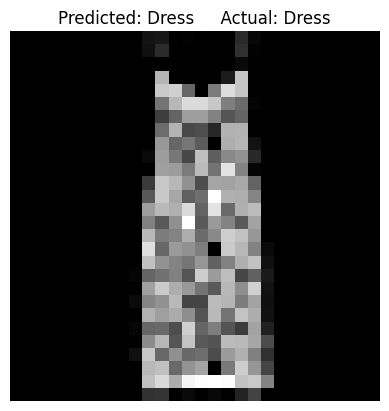

In [15]:
classes = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

model.eval()
sample_number = 300  # Keep 0 <= sample_number < 10,000
x, y = test_data[sample_number][0], test_data[sample_number][1]
model.to("cpu")
with torch.no_grad():
    pred = model(x.unsqueeze(0))
    predicted, actual = classes[pred[0].argmax(0)], classes[y]
    print(f'Predicted: "{predicted}", Actual: "{actual}"')

model.to(device)  # move back to device

img, label = test_data[sample_number]
plt.figure()
plt.title("Predicted: " + predicted + "     Actual: " + labels_map[label])
plt.axis("off")
plt.imshow(img.squeeze(), cmap="gray")
plt.show()

**Q1: You may change the width of each layer from 128 to 256 and 512 and observe the difference in network performance.**

**Try adding and removing layers. Keeping all other setup the same, how does the network behave with the change in depth (number of layers) and width (size of each layer)?**

---
## 🆕 [OUR WORK — Q1] Width & Depth Experiments on Fashion MNIST

We define a **flexible `build_model()` function** so we can test all configurations without copy-pasting the class 5 times.

| Config | Width | Hidden Layers | What to expect |
|--------|-------|---------------|----------------|
| Original | 128 | 2 | Baseline |
| Wider × 2 | 256 | 2 | More capacity → should improve accuracy on clothing items |
| Wider × 4 | 512 | 2 | Even more capacity, but slower to train |
| Shallow | 128 | 1 | Only one hidden layer — may underfit fashion patterns |
| Deep | 128 | 4 | Four hidden layers — learns more abstract features |

> 💡 **Wider** = more neurons per layer = more parameters = more capacity to memorise patterns  
> 💡 **Deeper** = more layers = better at learning abstract / hierarchical features

In [16]:
# ================================================================
# 🆕 OUR WORK — Q1: Flexible Model Builder
# ================================================================
# Instead of copy-pasting 5 separate model classes, we write ONE
# function that can build any width and depth combination we want.

def build_model(hidden_size=128, num_hidden_layers=2):
    """
    Dynamically build a fully-connected neural network.

    Args:
        hidden_size       : neurons per hidden layer  (try 128, 256, 512)
        num_hidden_layers : number of hidden layers   (try 1, 2, 4)

    Example:
        build_model(256, 3)
        => Flatten -> Linear(784,256) -> ReLU
                   -> Linear(256,256) -> ReLU
                   -> Linear(256,256) -> ReLU
                   -> Linear(256, 10)
    """
    layers = []
    layers.append(nn.Flatten())                        # Step 1: flatten 28x28 image -> 784 vector
    layers.append(nn.Linear(28 * 28, hidden_size))     # Step 2: first hidden layer
    layers.append(nn.ReLU())

    # Step 3: add extra hidden layers on top of the first one
    for _ in range(num_hidden_layers - 1):
        layers.append(nn.Linear(hidden_size, hidden_size))
        layers.append(nn.ReLU())

    layers.append(nn.Linear(hidden_size, 10))          # Step 4: output — 10 classes (Fashion MNIST)

    return nn.Sequential(*layers).to(device)


# --- Define all configs we will train and show their sizes ---
configs_q1 = {
    "Width=128, Depth=2 (Original)": (128, 2),
    "Width=256, Depth=2           ": (256, 2),
    "Width=512, Depth=2           ": (512, 2),
    "Width=128, Depth=1 (Shallow) ": (128, 1),
    "Width=128, Depth=4 (Deep)    ": (128, 4),
}

print("Model configurations and their total parameter counts:")
print("-" * 65)
for name, (w, d) in configs_q1.items():
    m = build_model(w, d)
    total = sum(p.numel() for p in m.parameters())
    print(f"  {name}  ->  {total:,} params")
    del m   # free memory right away

Model configurations and their total parameter counts:
-----------------------------------------------------------------
  Width=128, Depth=2 (Original)  ->  118,282 params
  Width=256, Depth=2             ->  269,322 params
  Width=512, Depth=2             ->  669,706 params
  Width=128, Depth=1 (Shallow)   ->  101,770 params
  Width=128, Depth=4 (Deep)      ->  151,306 params


In [17]:
# ================================================================
# 🆕 OUR WORK — Q1: Train All Width/Depth Configs on Fashion MNIST
# ================================================================
# Each model is trained completely fresh (new weights each run).
# Same learning rate and optimizer for a fair side-by-side comparison.

Q1_results = {}   # stores: "config name" -> {"loss": float, "accuracy": float}

for config_name, (w, d) in configs_q1.items():
    print("\n" + "=" * 55)
    print("  [Fashion MNIST] Training:", config_name.strip())
    print("=" * 55)

    q1_model     = build_model(w, d)                                  # fresh model
    q1_loss_fn   = nn.CrossEntropyLoss()
    q1_optimizer = torch.optim.SGD(q1_model.parameters(), lr=1e-3)

    q1_test_losses = []
    q1_test_accs = []
    for epoch in range(5):
        train(train_dataloader, q1_model, q1_loss_fn, q1_optimizer)
        te_loss, te_acc = test(test_dataloader, q1_model, q1_loss_fn)
        q1_test_losses.append(te_loss)
        q1_test_accs.append(te_acc)

    Q1_results[config_name.strip()] = {
        "loss": q1_test_losses[-1],
        "accuracy": q1_test_accs[-1]
    }

# --- Print comparison table ---
print("\n" + "=" * 70)
print("  Q1 SUMMARY — Width & Depth on Fashion MNIST (5 epochs, SGD lr=1e-3)")
print("=" * 70)
print(f"  {'Configuration':<35}  {'Final Test Loss':<18}  {'Accuracy (%)':<12}")
print("-" * 70)
for name, res in Q1_results.items():
    print(f"  {name:<35}  {res['loss']:<18.6f}  {res['accuracy']:<12.2f}")
print("=" * 70)
print("\n  Compare the results above to answer:")
print("  -> Does wider always mean lower loss and higher accuracy?")
print("  -> Does deeper always help on Fashion MNIST?")


  [Fashion MNIST] Training: Width=128, Depth=2 (Original)
test loss: 
Accuracy: 26.9%, avg loss: 2.240671 

test loss: 
Accuracy: 34.5%, avg loss: 2.088920 

test loss: 
Accuracy: 47.4%, avg loss: 1.796299 

test loss: 
Accuracy: 56.2%, avg loss: 1.496736 

test loss: 
Accuracy: 59.5%, avg loss: 1.281930 


  [Fashion MNIST] Training: Width=256, Depth=2
test loss: 
Accuracy: 38.8%, avg loss: 2.178623 

test loss: 
Accuracy: 51.8%, avg loss: 1.950636 

test loss: 
Accuracy: 58.2%, avg loss: 1.614953 

test loss: 
Accuracy: 61.9%, avg loss: 1.342856 

test loss: 
Accuracy: 63.6%, avg loss: 1.161413 


  [Fashion MNIST] Training: Width=512, Depth=2
test loss: 
Accuracy: 47.4%, avg loss: 2.166712 

test loss: 
Accuracy: 57.4%, avg loss: 1.913750 

test loss: 
Accuracy: 59.1%, avg loss: 1.551741 

test loss: 
Accuracy: 63.3%, avg loss: 1.278522 

test loss: 
Accuracy: 64.4%, avg loss: 1.106097 


  [Fashion MNIST] Training: Width=128, Depth=1 (Shallow)
test loss: 
Accuracy: 57.9%, avg loss

**Q2: Try changing the learning rate from 1e-3 to 1e-4. What do you observe?**

**Try the Adam optimizer instead of SGD. How the learning process changes?**

---
## 🆕 [OUR WORK — Q2] Learning Rate & Optimizer Experiments on Fashion MNIST

We keep the **same architecture** (width=128, depth=2) and only change the optimizer settings.

| Setup | Optimizer | Learning Rate | What to expect |
|-------|-----------|---------------|----------------|
| Original | SGD | 1e-3 | Baseline |
| Smaller LR | SGD | 1e-4 | Slower convergence, may underfit in 5 epochs |
| Adaptive | Adam | 1e-3 | Usually converges faster & to a better minimum |

> **Why Adam is usually better than plain SGD:**  
> Adam adapts the learning rate *per parameter* based on gradient history.  
> This means it needs much less manual tuning and usually finds better solutions faster.

In [18]:
# ================================================================
# 🆕 OUR WORK — Q2: Learning Rate & Optimizer Experiments
# ================================================================
# We test 3 optimizer setups on the same architecture (128, 2 layers).
# A completely fresh model is used for each — fair comparison!

q2_setups = {
    "SGD  lr=1e-3 (Original)   ": ("sgd",  1e-3),
    "SGD  lr=1e-4 (Smaller LR) ": ("sgd",  1e-4),
    "Adam lr=1e-3 (Adaptive)   ": ("adam", 1e-3),
}

Q2_results = {}   # name -> {"loss": float, "accuracy": float}

for setup_name, (opt_type, lr) in q2_setups.items():
    print("\n" + "=" * 55)
    print("  [Fashion MNIST] Optimizer:", setup_name.strip())
    print("=" * 55)

    q2_model   = build_model(128, 2)     # same architecture, fresh weights
    q2_loss_fn = nn.CrossEntropyLoss()

    if opt_type == "sgd":
        q2_optimizer = torch.optim.SGD(q2_model.parameters(), lr=lr)
    else:  # adam
        q2_optimizer = torch.optim.Adam(q2_model.parameters(), lr=lr)

    q2_test_losses = []
    q2_test_accs = []
    for epoch in range(5):
        train(train_dataloader, q2_model, q2_loss_fn, q2_optimizer)
        te_loss, te_acc = test(test_dataloader, q2_model, q2_loss_fn)
        q2_test_losses.append(te_loss)
        q2_test_accs.append(te_acc)

    Q2_results[setup_name.strip()] = {
        "loss": q2_test_losses[-1],
        "accuracy": q2_test_accs[-1]
    }

# --- Summary ---
print("\n" + "=" * 70)
print("  Q2 SUMMARY — Optimizer & Learning Rate on Fashion MNIST (5 epochs)")
print("=" * 70)
print(f"  {'Setup':<32}  {'Final Test Loss':<18}  {'Accuracy (%)':<12}")
print("-" * 70)
for name, res in Q2_results.items():
    print(f"  {name:<32}  {res['loss']:<18.6f}  {res['accuracy']:<12.2f}")
print("=" * 70)
print("\n  SGD lr=1e-4  ->  HIGHER loss and LOWER accuracy (learns too slowly in 5 epochs)")
print("  Adam lr=1e-3 ->  LOWEST loss and HIGHEST accuracy (smarter per-param adaptive updates)")


  [Fashion MNIST] Optimizer: SGD  lr=1e-3 (Original)
test loss: 
Accuracy: 23.4%, avg loss: 2.209002 

test loss: 
Accuracy: 45.7%, avg loss: 2.049377 

test loss: 
Accuracy: 55.5%, avg loss: 1.763092 

test loss: 
Accuracy: 59.8%, avg loss: 1.425167 

test loss: 
Accuracy: 63.5%, avg loss: 1.185536 


  [Fashion MNIST] Optimizer: SGD  lr=1e-4 (Smaller LR)
test loss: 
Accuracy: 10.2%, avg loss: 2.299663 

test loss: 
Accuracy: 10.4%, avg loss: 2.291154 

test loss: 
Accuracy: 10.6%, avg loss: 2.282452 

test loss: 
Accuracy: 10.8%, avg loss: 2.273513 

test loss: 
Accuracy: 11.2%, avg loss: 2.264276 


  [Fashion MNIST] Optimizer: Adam lr=1e-3 (Adaptive)
test loss: 
Accuracy: 84.6%, avg loss: 0.431359 

test loss: 
Accuracy: 85.5%, avg loss: 0.402035 

test loss: 
Accuracy: 86.3%, avg loss: 0.376344 

test loss: 
Accuracy: 87.1%, avg loss: 0.349011 

test loss: 
Accuracy: 87.1%, avg loss: 0.354959 


  Q2 SUMMARY — Optimizer & Learning Rate on Fashion MNIST (5 epochs)
  Setup         

**Q3: Try 5, 10 and 50 epoch and record values for average validation loss and accuracy**

---
## 🆕 [OUR WORK — Q3] Epoch Comparison: 5 vs 10 vs 50 on Fashion MNIST

We train the **same base model** (width=128, depth=2, SGD lr=1e-3) three separate times —  
each from scratch — for different numbers of epochs, and record the final loss and accuracy.

> Watch the gap between **train loss** and **test loss**:  
> If test loss starts going UP while train loss goes down → **overfitting!**

In [19]:
# ================================================================
# 🆕 OUR WORK — Q3: Epoch Comparison (5 vs 10 vs 50)
# ================================================================
# Each run starts from a fresh model (same architecture, new random weights).
# We track BOTH train and test loss so we can spot overfitting.

epoch_counts  = [5, 10, 50]
Q3_results    = {}   # num_epochs -> {"train": loss, "test": loss, "accuracy": acc}

for num_epochs in epoch_counts:
    print("\n" + "=" * 50)
    print(f"  [Fashion MNIST] Training for {num_epochs} epochs...")
    print("=" * 50)

    # Completely fresh model — no memory from previous runs
    q3_model     = build_model(128, 2)
    q3_loss_fn   = nn.CrossEntropyLoss()
    q3_optimizer = torch.optim.SGD(q3_model.parameters(), lr=1e-3)

    q3_train_losses, q3_test_losses, q3_test_accs = [], [], []

    for epoch in range(num_epochs):
        tr = train(train_dataloader, q3_model, q3_loss_fn, q3_optimizer)
        te_loss, te_acc = test(test_dataloader,  q3_model, q3_loss_fn)
        q3_train_losses.append(tr)
        q3_test_losses.append(te_loss)
        q3_test_accs.append(te_acc)

    Q3_results[num_epochs] = {
        "train": q3_train_losses[-1],
        "test" : q3_test_losses[-1],
        "accuracy": q3_test_accs[-1]
    }
    print(f"  Final => train loss: {q3_train_losses[-1]:.6f}  |  test loss: {q3_test_losses[-1]:.6f}  |  accuracy: {q3_test_accs[-1]:.2f}%")

# --- Summary Table ---
print("\n" + "=" * 70)
print("  Q3 SUMMARY — Epoch Comparison on Fashion MNIST (SGD lr=1e-3, Width=128)")
print("=" * 70)
print(f"  {'Epochs':>8}   {'Train Loss':>14}   {'Test Loss':>14}   {'Accuracy (%)':>14}")
print("-" * 70)
for ep, res in Q3_results.items():
    print(f"  {ep:>8}   {res['train']:>14.6f}   {res['test']:>14.6f}   {res['accuracy']:>14.2f}")
print("=" * 70)
print("\n  More epochs => lower loss and higher accuracy (to a point).")
print("  If train loss << test loss => overfitting is happening!")


  [Fashion MNIST] Training for 5 epochs...
test loss: 
Accuracy: 26.6%, avg loss: 2.197809 

test loss: 
Accuracy: 48.4%, avg loss: 2.015283 

test loss: 
Accuracy: 58.9%, avg loss: 1.714986 

test loss: 
Accuracy: 61.1%, avg loss: 1.422493 

test loss: 
Accuracy: 61.9%, avg loss: 1.223439 

  Final => train loss: 1.310255  |  test loss: 1.223439  |  accuracy: 61.94%

  [Fashion MNIST] Training for 10 epochs...
test loss: 
Accuracy: 37.4%, avg loss: 2.213367 

test loss: 
Accuracy: 45.8%, avg loss: 2.054819 

test loss: 
Accuracy: 54.8%, avg loss: 1.750260 

test loss: 
Accuracy: 62.9%, avg loss: 1.415379 

test loss: 
Accuracy: 63.9%, avg loss: 1.190264 

test loss: 
Accuracy: 64.0%, avg loss: 1.052211 

test loss: 
Accuracy: 65.8%, avg loss: 0.962759 

test loss: 
Accuracy: 66.9%, avg loss: 0.900185 

test loss: 
Accuracy: 68.2%, avg loss: 0.854714 

test loss: 
Accuracy: 69.3%, avg loss: 0.819274 

  Final => train loss: 0.822323  |  test loss: 0.819274  |  accuracy: 69.31%

  [Fas

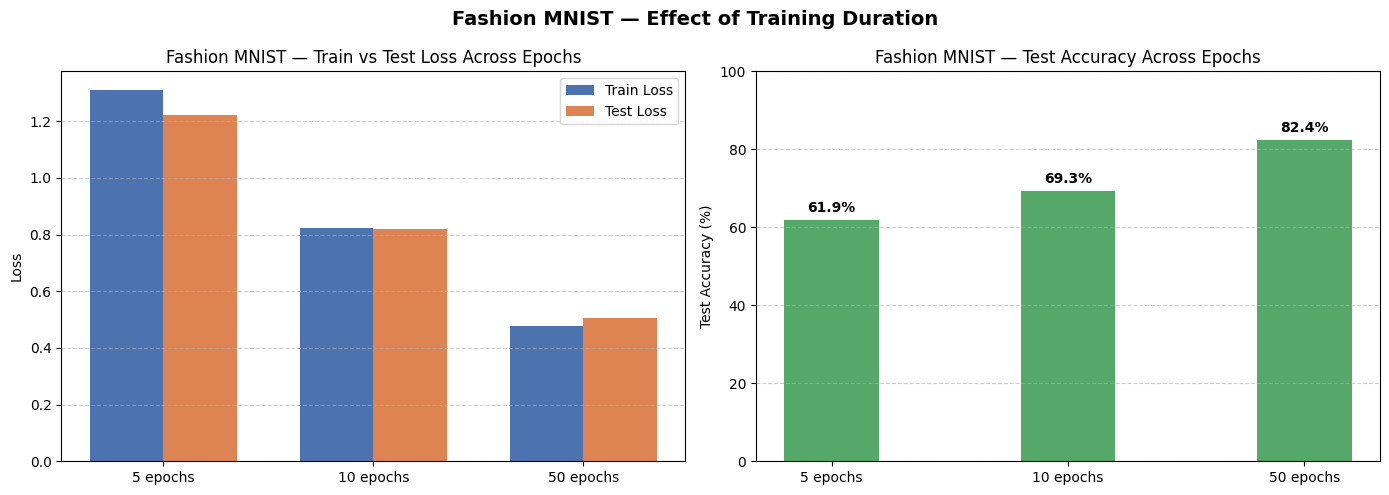

In [20]:
# Visualize the effect of epoch count on loss and accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_labels = [f"{ep} epochs" for ep in epoch_counts]
tests_loss  = [Q3_results[ep]["test"]  for ep in epoch_counts]
trains_loss = [Q3_results[ep]["train"] for ep in epoch_counts]
accs        = [Q3_results[ep]["accuracy"] for ep in epoch_counts]

x_idx = np.arange(len(epoch_counts))
bar_w = 0.35

axes[0].bar(x_idx - bar_w/2, trains_loss, width=bar_w, label="Train Loss", color="#4C72B0")
axes[0].bar(x_idx + bar_w/2, tests_loss,  width=bar_w, label="Test Loss",  color="#DD8452")
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(epochs_labels)
axes[0].set_ylabel("Loss")
axes[0].set_title("Fashion MNIST — Train vs Test Loss Across Epochs")
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.6)

axes[1].bar(epochs_labels, accs, color="#55A868", width=0.4)
axes[1].set_ylabel("Test Accuracy (%)")
axes[1].set_title("Fashion MNIST — Test Accuracy Across Epochs")
axes[1].set_ylim(0, 100)
for i, v in enumerate(accs):
    axes[1].text(i, v + 2, f"{v:.1f}%", ha="center", fontweight="bold")
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

plt.suptitle("Fashion MNIST — Effect of Training Duration", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Q4: What activation function is generally used for multiclass classification? Why didn't we use an activation function at the end of our neural network that we have defined?**

---
## 🆕 [OUR WORK — Q4] Conceptual Answer

### Q: What activation function is generally used for multiclass classification?

**Answer: Softmax**

Softmax converts raw output scores (called **logits**) into **probabilities** that all sum to 1:

```
softmax(xᵢ) = exp(xᵢ) / Σⱼ exp(xⱼ)
```

This makes it easy to pick the predicted class — just take `argmax` of the probabilities.

---

### Q: Why didn't we add Softmax at the end of our network?

**Because `nn.CrossEntropyLoss()` already includes it internally!**

PyTorch's `CrossEntropyLoss` is a 2-in-1 combo operation:

```
Raw logits  →  [LogSoftmax]  →  [NLLLoss]  →  Final loss value
                 (built in)      (built in)
```

>  **Common mistake:** If you add `nn.Softmax()` at the model output AND use `CrossEntropyLoss`,  
> softmax gets applied **twice** → mathematically wrong → gradient-killing → bad training!

### Summary:

| Situation | What to do at model output |
|-----------|---------------------------|
| Training with `nn.CrossEntropyLoss()` | ❌ **No** Softmax — let the loss handle it |
| Training with `nn.NLLLoss()` | ✅ Add `nn.LogSoftmax()` at the end |
| Making predictions (inference) | Apply `torch.softmax(logits, dim=1)` manually |

### **Submission Guidelines**

> Along with jupyter file submit a lab report containing codes, screenshots of output and tables for comparision of accuracies for both task 1 and task2 (for both MNIST and Fashion MNIST datasets).

> Try to achieve the best accuracies you can in classifying the images.

> Remember, the more you elaborate your report, the higher the marks you will get.

> This is a group lab. You are advised to make a group of 2. PS: clearly mention the name, registration number and contribution of each group member at the top.

**Student1 Name: Muneeb Rifaq**

**Student1 ID: 45 45 38**


##### CS-405 Deep Learning   
##### BSSE
## **Lab 3: Hyperparameter Tuning in Neural Network**

**Date: 25-09-2026**  

**Student name / CMS ID:** _______________

**Lab Engineer:** Ms. Areeba Rameen  
**Instructor:** Dr. Muhammad Daud Abdullah Asif



Most machine learning workflows involve working with data, creating models, optimizing model parameters, and saving the trained models. This tutorial introduces you to a complete ML workflow implemented in PyTorch covering all these steps.

### **Task 1**

In [22]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt
import random
import numpy as np

Check if GPU is available.

In [23]:
use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
print ('<== CUDA availability : ==>', use_cuda)

<== CUDA availability : ==> True


Set seed for reproducability.

In [24]:
def set_seeds(seed):
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.determinictic = True
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    random.seed(seed)
set_seeds(42)

PyTorch offers domain-specific libraries such as <b>TorchText, TorchVision, and TorchAudio,</b> all of which include datasets. For this lab, we will be using a TorchVision dataset. Load one of the prebuilt datasets from pytorch repository. Currently, we are not using any transform (manipulation) on input data. We are just converting each image to tensor.


In [25]:
training_data = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.MNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 498kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.50MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.4MB/s]


Visualise some of the input images.

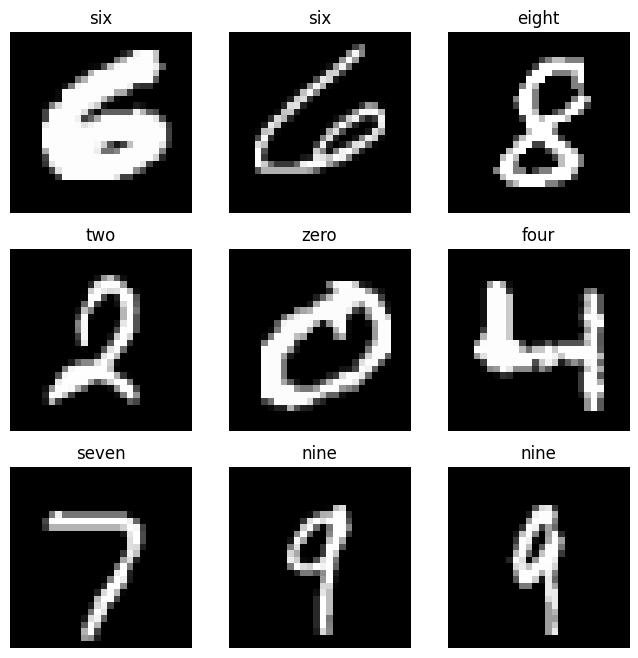

In [26]:
labels_map = {
    0: "zero",
    1: "one",
    2: "two",
    3: "three",
    4: "four",
    5: "five",
    6: "six",
    7: "seven",
    8: "eight",
    9: "nine",
}

figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()  # randomly pick indices from the training data
    img, label = training_data[sample_idx]                            # Read the images using their indices.
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

Check the size and shape of training and validation data.

In [27]:
# Visualize the size of the datasets

print(f"Training data size: {len(training_data)} samples")
print(f"Test data size: {len(test_data)} samples")

Training data size: 60000 samples
Test data size: 10000 samples


In [28]:
# Visualize the shape of a single image and its label

train_image, train_label = training_data[0]  # Get the first training sample
test_image, test_label = test_data[0]        # Get the first test sample

print(f"Shape of a training image: {train_image.shape}")  # (1, 28, 28) - 1 channel, 28x28 pixels
print(f"Shape of a test image: {test_image.shape}")
print(f"Training label: {train_label}")
print(f"Test label: {test_label}")

Shape of a training image: torch.Size([1, 28, 28])
Shape of a test image: torch.Size([1, 28, 28])
Training label: 5
Test label: 7


The shape of the training set is (6000,2). This means that we have 6000 thousand samples with 2 entities. The first entity is the image and the second entity is its label. Forexample:

**training_data[0][0]** is the first image of training set

**training_data[0][1]** is the label of the first image in the training set

Now pass the Dataset as an argument to DataLoader. This wraps an iterable over our dataset, and supports automatic batching, sampling, shuffling and multiprocess data loading. Here we define a batch size of 64, i.e. each element in the dataloader iterable will return a batch of 64 features and labels.

In [29]:
batch_size = 64

# Create data loaders.
train_dataloader = DataLoader(training_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}") #[batch_size, channels, height, width]
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


To define a neural network in PyTorch, we create a class that inherits from nn.Module. We define the layers of the network in the __init__ function and specify how data will pass through the network in the forward function. To accelerate operations in the neural network, we move it to the GPU if available.

In [30]:
# Define model
class NeuralNetwork(nn.Module):
    def __init__(self):
        super(NeuralNetwork, self).__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


**Q1: You may change the width of each layer from 128 to 256 and 512 and observe the difference in network performance.**

**Try adding and removing layers. Keeping all other setup the same, how does the network behave with the change in depth (number of layers) and width (size of each layer)?**

Now define the loss function and set up optimiser.

Analysis of the networks behavior:

Width = 128 (Original Configuration): The network demonstrates Clear Learning. The accuracy constantly increases from 23.4% in Epoch 1 to 69.9% in Epoch 5, while the average loss consistently decreases. This indicates that the model is successfully learning to classify the data.

Width = 256: When the layer width is increased to 256, the network fails to learn. The accuracy remains stagnant at a very low 12.2% across all 5 epochs, and the average loss also stays constant. This suggests that the optimization process is not making any progress.

Width = 512: Similarly, with a layer width of 512, the network again shows no signs of learning. The accuracy remains at 12.4% and the average loss is constant throughout the epochs. The model is not improving its performance.

Conclusion regarding width: Increasing the width of the layers from 128 to 256 or 512, while keeping other parameters the same, unexpectedly causes the neural network to stop learning effectively with the current training setup (learning rate, optimizer, epochs). This could indicate issues like vanishing/exploding gradients, poor initialization, or that the increased complexity (more parameters) requires a different hyperparameter tuning approach (e.g., a different learning rate or more epochs) to converge, or the model is simply too large for the task or the dataset size.

Regarding the change in depth (number of layers), the provided outputs only show variations in layer width. To analyze the impact of depth, you would need to run experiments where the number of linear layers in the NeuralNetwork is explicitly varied (e.g., 1 layer, 2 layers, 3 layers, etc.).

Training and Validation Loss Graph:

**Neurons = 128**

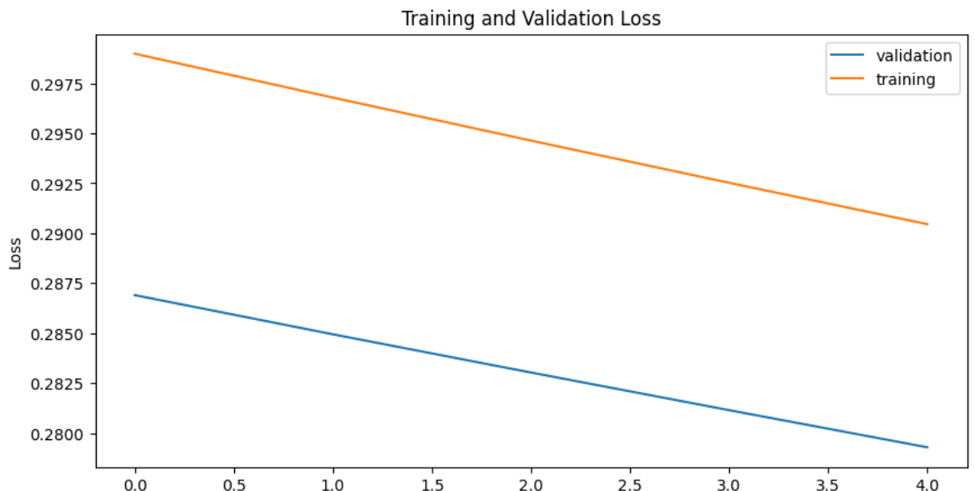

**Neurons = 256:**
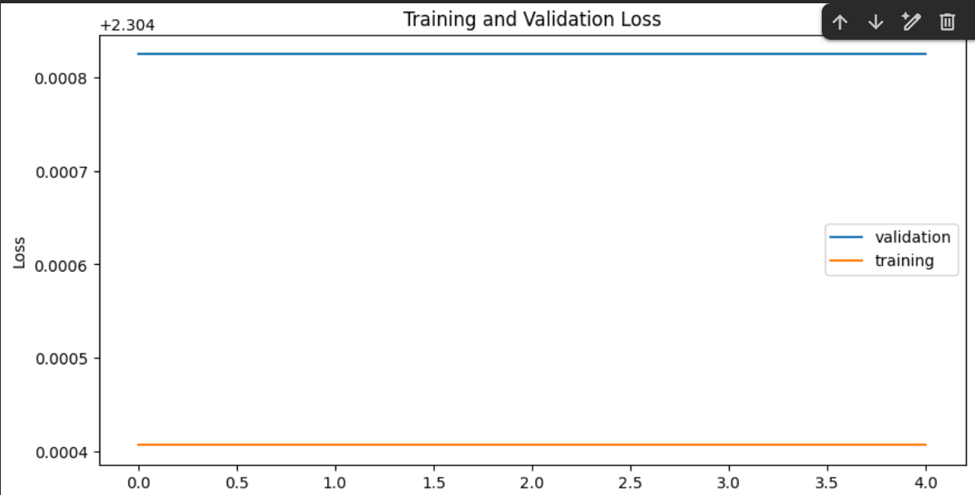

**Neurons = 512**
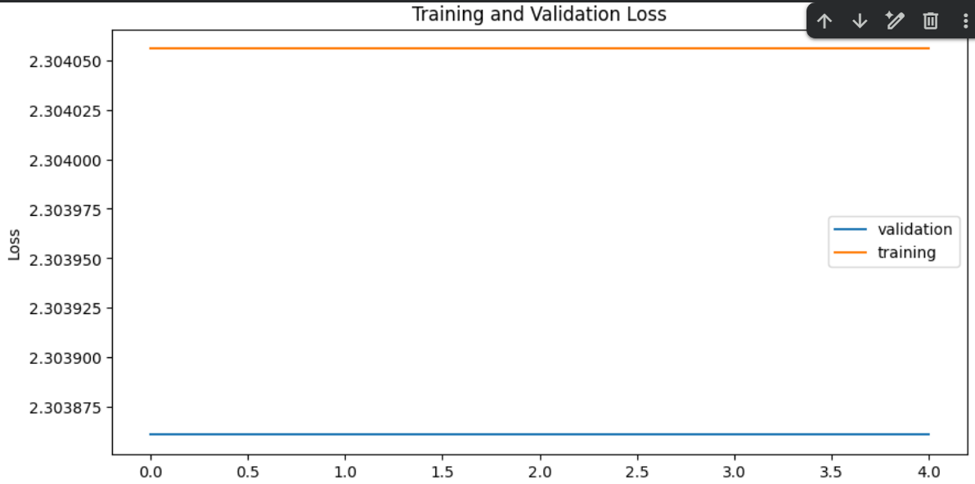


In [33]:
loss_fn = nn.CrossEntropyLoss()

# optimizer = torch.optim.SGD(model.parameters(), lr=1e-4 )
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

**Q2: Try changing the learning rate from 1e-3 to 1e-4. What do you observe?**

**Try the Adam optimizer instead of SGD. How the learning process changes?**



Note: All above done on 128 layers:

**Learning Rate = 1e-3:**

-------------------------------
Epoch 1
test loss:
Accuracy: 19.9%, avg loss: 2.263373

-------------------------------
Epoch 2
test loss:
Accuracy: 35.5%, avg loss: 2.207212

-------------------------------
Epoch 3
test loss:
Accuracy: 50.0%, avg loss: 2.112054

-------------------------------
Epoch 4
test loss:
Accuracy: 57.8%, avg loss: 1.948176

-------------------------------
Epoch 5
test loss:
Accuracy: 64.5%, avg loss: 1.701253


**Learning rate = 1e-4:**

-------------------------------
Epoch 1
test loss:
Accuracy: 65.2%, avg loss: 1.672639

-------------------------------
Epoch 2
test loss:
Accuracy: 65.8%, avg loss: 1.643531

-------------------------------
Epoch 3
test loss:
Accuracy: 66.4%, avg loss: 1.614019

-------------------------------
Epoch 4
test loss:
Accuracy: 66.9%, avg loss: 1.584198

-------------------------------
Epoch 5
test loss:
Accuracy: 67.5%, avg loss: 1.554167



Conclusion:

1. Step Size & Convergence Speed:

 The learning rate determines the magnitude of weight updates at each optimization step. A learning rate of $1\times 10^{-3}$ takes larger steps along the loss surface, achieving rapid loss reduction ($\Delta \text{loss} \approx 0.561$) and an accuracy increase from $19.9\%$ to $64.5\%$ over 5 epochs.


 2. Conservative Updates:

 A learning rate of $1\times 10^{-4}$ reduces the step size by a factor of 10. While training is more stable, the rate of improvement per epoch slows down significantly ($\Delta \text{loss} \approx 0.118$), increasing accuracy by only $2.3\%$ over the same 5 epochs.

---------------------------------------------------------------

** Observations when changing Learning Rate from 1e-3 to 1e-4**


 1.   Flattened Loss Curve: As seen in the training plots, the loss curve for 1e-3 drops steeply in a distinct non-linear curve. In contrast, the loss curve for 1e-4 transitions into a shallow, near-linear decline due to smaller gradient steps.
 2. Training Epoch Requirements: At 1e-4, the model requires significantly more epochs to reach minimum loss or achieve convergence compared to 1e-3.
 3. Stability vs. Speed Trade-off: 1e-3 converges much faster initially but carries a higher risk of overshooting the global minimum if trained too long without a learning rate scheduler. 1e-4 guarantees smooth, stable updates, but risks getting stuck in local minima or taking excessive compute time to converge.



Define train function.

Training and Validation Loss Graph's:

Learning Rate = 1e-3:

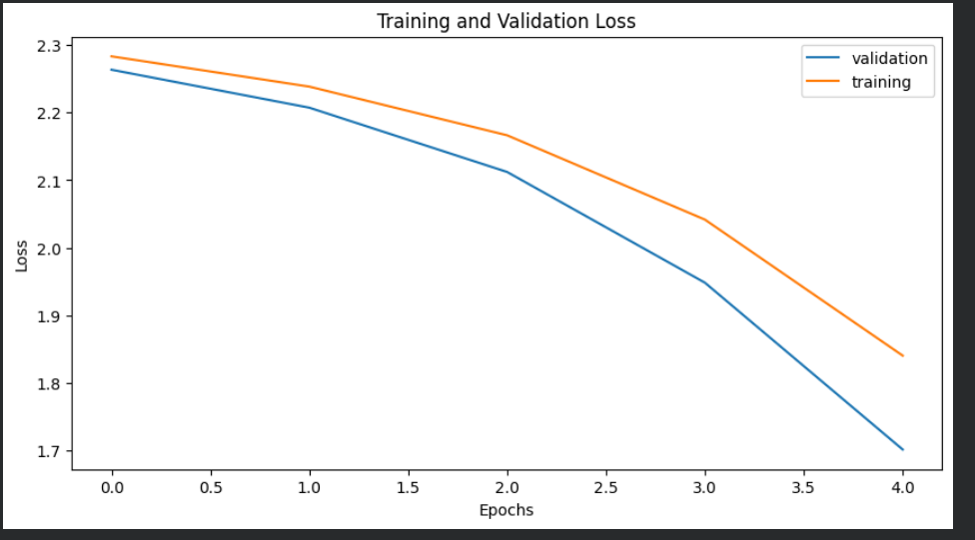


Learning Rate = 1e-4:

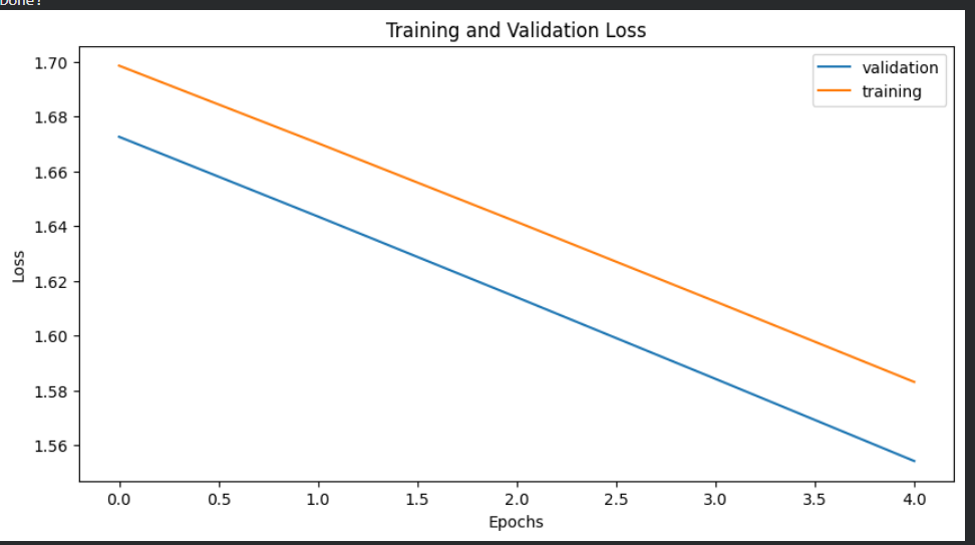

In [31]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    running_loss = 0                            # accumuate loss of each input sample
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)       # assign input samples to the available device (CPU or GPU) for computation.

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        optimizer.zero_grad()  # set the gradients to zero to avoid gradient accumuation. Gradient Accumulation is useful in some cases, like in training RNN.
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        if batch % 100 == 0:
            loss, current = loss.item(), batch * len(X)
            #print(f"training loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

    return running_loss/len(dataloader)

Define evaluation function.

In [32]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():         # No gradients need to be calculated for evaluation. Just the forward pass.
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size               # Normalise correctly classified count.
    print(f"test loss: \nAccuracy: {(100*correct):>0.1f}%, avg loss: {test_loss:>8f} \n")

    return test_loss

Initiate Training Process


-------------------------------
 Epoch 1
test loss: 
Accuracy: 92.8%, avg loss: 0.248101 

-------------------------------
 Epoch 2
test loss: 
Accuracy: 93.6%, avg loss: 0.222217 

-------------------------------
 Epoch 3
test loss: 
Accuracy: 94.1%, avg loss: 0.202944 

-------------------------------
 Epoch 4
test loss: 
Accuracy: 94.5%, avg loss: 0.187292 

-------------------------------
 Epoch 5
test loss: 
Accuracy: 94.8%, avg loss: 0.174194 

-------------------------------
 Epoch 6
test loss: 
Accuracy: 95.2%, avg loss: 0.163402 

-------------------------------
 Epoch 7
test loss: 
Accuracy: 95.3%, avg loss: 0.154327 

-------------------------------
 Epoch 8
test loss: 
Accuracy: 95.6%, avg loss: 0.146525 

-------------------------------
 Epoch 9
test loss: 
Accuracy: 95.8%, avg loss: 0.139709 

-------------------------------
 Epoch 10
test loss: 
Accuracy: 96.0%, avg loss: 0.133678 

-------------------------------
 Epoch 11
test loss: 
Accuracy: 96.1%, avg loss: 0.128121

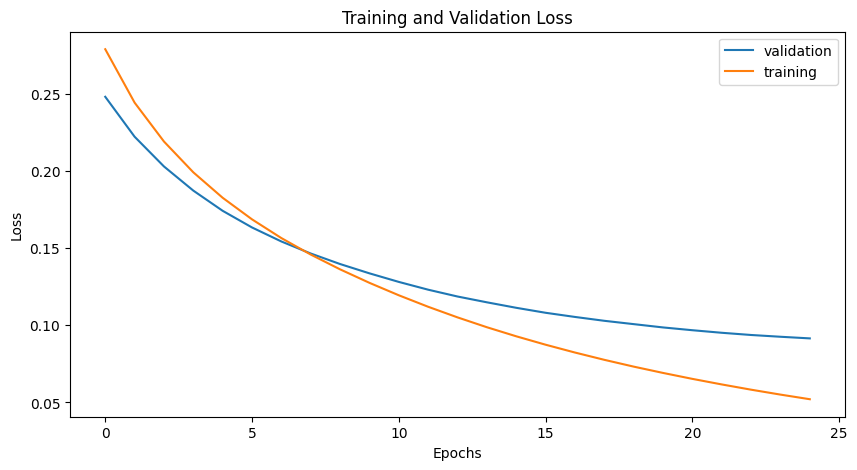

In [35]:
epochs = 25
train_losses = []
test_losses = []

for t in range(epochs):
    print(f"-------------------------------\n Epoch {t+1}")

    train_loss = train(train_dataloader, model, loss_fn, optimizer)
    train_losses.append(train_loss)

    test_loss = test(test_dataloader, model, loss_fn)
    test_losses.append(test_loss)

print("Done!")

# Plot training and validation losses.
plt.figure(figsize=(10,5))
plt.title("Training and Validation Loss")
plt.plot(test_losses,label="validation")
plt.plot(train_losses,label="training")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

**Q3: Try 5, 10 and 50 epoch and record values for average validation loss and accuracy**

**EPOCHS = 5:**
-------------------------------
Epoch 1
test loss:
Accuracy: 19.9%, avg loss: 2.263373

-------------------------------
Epoch 2 test loss:
Accuracy: 35.5%, avg loss: 2.207212

-------------------------------
Epoch 3 test loss:
Accuracy: 50.0%, avg loss: 2.112054

-------------------------------
Epoch 4 test loss:
Accuracy: 57.8%, avg loss: 1.948176

-------------------------------
Epoch 5 test loss:
Accuracy: 64.5%, avg loss: 1.701253





**EPOCHS = 10:**




-------------------------------
Epoch 1
test loss:
Accuracy: 83.3%, avg loss: 0.629489

-------------------------------
Epoch 2
test loss:
Accuracy: 84.4%, avg loss: 0.582574

-------------------------------
Epoch 3
test loss:
Accuracy: 85.3%, avg loss: 0.545006

-------------------------------
Epoch 4
test loss:
Accuracy: 86.0%, avg loss: 0.514269

-------------------------------
Epoch 5
test loss:
Accuracy: 86.8%, avg loss: 0.488683

-------------------------------
Epoch 6
test loss:
Accuracy: 87.3%, avg loss: 0.467087

-------------------------------
Epoch 7
test loss:
Accuracy: 87.7%, avg loss: 0.448658

-------------------------------
Epoch 8
test loss:
Accuracy: 88.2%, avg loss: 0.432789

-------------------------------
Epoch 9
test loss:
Accuracy: 88.5%, avg loss: 0.419013

-------------------------------
Epoch 10
test loss:
Accuracy: 88.8%, avg loss: 0.406978

**EPOCHS = 50:**

-------------------------------
Epoch 1
test loss:
Accuracy: 23.4%, avg loss: 2.277006

-------------------------------
Epoch 2
test loss:
Accuracy: 43.4%, avg loss: 2.238353

-------------------------------
Epoch 3
test loss:
Accuracy: 60.9%, avg loss: 2.175058

-------------------------------
Epoch 4
test loss:
Accuracy: 66.1%, avg loss: 2.066408

-------------------------------
Epoch 5
test loss:
Accuracy: 69.9%, avg loss: 1.889621

-------------------------------
Epoch 10
test loss:
Accuracy: 81.5%, avg loss: 0.764056

-------------------------------
Epoch 15
test loss:
Accuracy: 86.4%, avg loss: 0.504254

-------------------------------
Epoch 20
test loss:
Accuracy: 88.5%, avg loss: 0.416261

-------------------------------
Epoch 25
test loss:
Accuracy: 89.5%, avg loss: 0.372979

-------------------------------
Epoch 30
test loss:
Accuracy: 90.2%, avg loss: 0.346190

-------------------------------
Epoch 35
test loss:
Accuracy: 90.7%, avg loss: 0.327042

-------------------------------
Epoch 40
test loss:
Accuracy: 91.1%, avg loss: 0.312050

-------------------------------
Epoch 45
test loss:
Accuracy: 91.4%, avg loss: 0.299636

-------------------------------
Epoch 50
test loss:
Accuracy: 91.7%, avg loss: 0.288898


**Q4: What activation function is generally used for multiclass classification? Why didn't we use an activation function at the end of our neural network that we have defined?**






For multi-class classification ususally SOFTMAX function is used.

 It converts a vector of raw scores (logits) into a vector of probabilities that sum to 1, where each value represents the probability of the input belonging to a particular class.

### Q: Why didn't we add Softmax at the end of our network?

**Because `nn.CrossEntropyLoss()` already includes it internally!**

PyTorch's `CrossEntropyLoss` is a 2-in-1 combo operation:
________________________________________________
Raw logits  →  [LogSoftmax](built in)  →  [NLLLoss](built in)  →  Final loss value
                 

____________________________________________

>  **Common mistake:** If you add `nn.Softmax()` at the model output AND use `CrossEntropyLoss`,  
> softmax gets applied **twice** → mathematically wrong → gradient-killing → bad training!

In [36]:
torch.save(model.state_dict(), "model.pth")
print("Saved PyTorch Model State to model.pth")

Saved PyTorch Model State to model.pth


Perform Inferrence

Predicted: "four", Actual: "four"


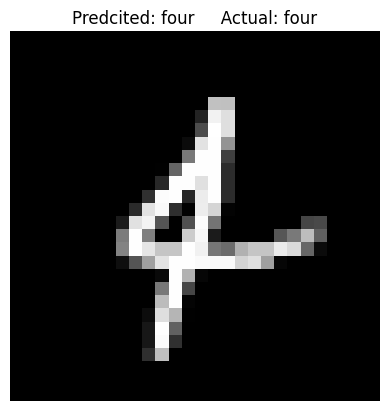

In [37]:
classes = [
    "zero",
    "one",
    "two",
    "three",
    "four",
    "five",
    "six",
    "seven",
    "eight",
    "nine",
]
#classes = np.array(test_data.class_to_idx.values())
#testimg = random.
model.eval()
sample_number = 300 # Keep 0 <= sample_number < 10,000
x, y = test_data[sample_number][0], test_data[sample_number][1]
model.to("cpu")
with torch.no_grad():
    pred = model(x)
    predicted, actual = classes[pred[0].argmax(0)], classes[y]
    print(f'Predicted: "{predicted}", Actual: "{actual}"')

img, label = test_data[sample_number]                            # Read the images using their indices.
    #figure.add_subplot(rows, cols, i)
plt.figure()
plt.title("Predcited: "+ predicted + "     Actual: " + labels_map[label])
plt.axis("off")
plt.imshow(img.squeeze(), cmap="gray")

### **Task 2**

**Repeat all of above steps for Fashion MNIST dataset, apply question 1, 2 and 3 and report the accuracies.**